In [1]:
import os
import torch

# --- ローカルGPUの設定 ---
# あなたのPCに搭載されているGPU（通常は1台）をPyTorchから見えるように設定します。
# '0' を指定することで、最初の（そして多くの場合唯一の）GPUが選択されます。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

# --- 確認のためのコード ---
if torch.cuda.is_available():
    print("✅ ローカルGPUが利用可能です。")
    print(f"PyTorchが見ているデバイス数: {torch.cuda.device_count()}")
    print(f"現在のデバイス (PyTorch Index): {torch.cuda.current_device()}")
    print(f"デバイス名: {torch.cuda.get_device_name(0)}")
else:
    print("❌ GPUが利用できません。PyTorchのインストールを確認してください。")

✅ ローカルGPUが利用可能です。
PyTorchが見ているデバイス数: 1
現在のデバイス (PyTorch Index): 0
デバイス名: NVIDIA TITAN X (Pascal)


In [2]:
# ==========================================
# Cell 1: ライブラリのインポート
# ==========================================
import os
import random
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Diffusers & Transformers
from diffusers import AutoencoderKL, DDPMScheduler, UNet2DConditionModel
from diffusers.optimization import get_cosine_schedule_with_warmup
from transformers import CLIPTextModel, CLIPTokenizer

# LoRA (PEFT)
from peft import LoraConfig, get_peft_model

# Seed固定
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)
print("Libraries imported and seed set.")

Libraries imported and seed set.


In [3]:
# ==========================================
# Cell 2: 設定とハイパーパラメータ
# ==========================================
# デバイス設定
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# パス設定
IMAGE_ROOT_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE_PATH = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
OUTPUT_DIR = "/home/masaki/mystudy/trained_models_l+Lmask_150"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ハイパーパラメータ
MODEL_NAME = "runwayml/stable-diffusion-v1-5"
BATCH_SIZE = 2
NUM_EPOCHS = 150
LEARNING_RATE = 1e-4
IMAGE_SIZE = 256
LATENT_SIZE = 32 # 256 // 8
LAMBDA = 10.0    # Masked Lossの重み (Proposed標準)

print(f"Device: {device}")
print(f"Output Dir: {OUTPUT_DIR}")
print(f"Lambda: {LAMBDA}")

Device: cuda
Output Dir: /home/masaki/mystudy/trained_models_l+Lmask_150
Lambda: 10.0


In [4]:
# ==========================================
# Cell 3: データセット定義 (BrainMetsDataset)
# ==========================================
class BrainMetsDataset(Dataset):
    def __init__(self, csv_file, image_root_dir, seg_dir, patient_ids, mode, image_size=256, latent_size=32):
        self.data = pd.read_csv(csv_file)
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        
        self.image_root_dir = image_root_dir
        self.seg_dir = seg_dir
        self.mode = mode
        self.image_size = image_size
        self.latent_size = latent_size
        self.pairs = self._create_pairs()
        
        # 画像の前処理: [0,1] -> [-1,1]
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((self.image_size, self.image_size), antialias=True),
            transforms.Normalize([0.5], [0.5])
        ])
        
        # マスクの前処理: [0,1] のまま、サイズはLatentに合わせる
        self.mask_transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((self.latent_size, self.latent_size), antialias=False) 
        ])

    def _create_pairs(self):
        pairs = []
        for _, group in self.data.groupby('PatientID'):
            # ベースラインとFutureがあるか確認
            baseline_scans = group[group['FinalPattern'] == 'Baseline']
            future_scans = group[group['FinalPattern'] != 'Baseline']
            if baseline_scans.empty or future_scans.empty: continue
            
            # ペアを作成
            for _, baseline_row in baseline_scans.iterrows():
                for _, future_row in future_scans.iterrows():
                    pairs.append({
                        "future_file": future_row['FileName'],
                        "condition": future_row['FinalPattern']
                    })
        print(f"Found {len(pairs)} pairs for '{self.mode}' set.")
        return pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pair = self.pairs[idx]
        
        try:
            # パス作成
            future_path = self._get_full_path(self.image_root_dir, pair['future_file'])
            mask_path = self._get_full_path(self.seg_dir, pair['future_file'], is_mask=True)

            # 読み込み & 前処理
            future_image = self._load_and_process_image(future_path) # -> pixel_values
            future_mask = self._load_and_process_mask(mask_path)     # -> masks

            # プロンプト作成
            # labelが "Progression" ならそのまま、それ以外もそのまま使いつつ、修飾語をつける
            condition_text = pair['condition']
            prompt = f"brain MRI, {condition_text}"

            return {
                "pixel_values": future_image,
                "masks": future_mask,
                "prompt": prompt
            }
        except Exception as e:
            print(f"Warning: Error loading {pair['future_file']} ({e}). Skipping.")
            return self.__getitem__((idx + 1) % len(self))
            
    def _get_full_path(self, directory, filename, is_mask=False):
        name_without_ext = filename.replace('.nii.gz', '')
        suffix = "_0000.nii.gz" if not is_mask else ".nii.gz"
        return os.path.join(directory, f"{name_without_ext}{suffix}")

    def _load_and_process_image(self, path):
        nii = nib.load(path)
        data = nii.get_fdata().astype('float32')
        # 中央スライス
        slice_img = data[:, :, data.shape[2] // 2]
        # Min-Max Normalization -> [0, 1]
        if slice_img.max() > slice_img.min():
            slice_img = (slice_img - slice_img.min()) / (slice_img.max() - slice_img.min())
        # Transform -> [-1, 1] & (3, H, W)
        image = self.transform(slice_img).repeat(3, 1, 1)
        return image

    def _load_and_process_mask(self, path):
        nii = nib.load(path)
        data = nii.get_fdata().astype('float32')
        slice_img = data[:, :, data.shape[2] // 2]
        # マスクは [0, 1] のまま
        mask = self.mask_transform(slice_img)
        return mask

print("Dataset class defined.")

Dataset class defined.


In [5]:
# ==========================================
# Cell 4: データ分割とローダー作成
# ==========================================
# 全患者IDの取得
full_df = pd.read_csv(CSV_FILE_PATH)
patient_ids = full_df['PatientID'].unique()

# 分割 (Train:70%, Temp:30% -> Val:15%, Test:15%)
train_patient_ids, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
val_patient_ids, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

print(f"Patients - Train: {len(train_patient_ids)}, Val: {len(val_patient_ids)}, Test: {len(test_patient_ids)}")

# データセットインスタンス
train_dataset = BrainMetsDataset(CSV_FILE_PATH, IMAGE_ROOT_DIR, SEG_DIR, train_patient_ids, mode='train')
val_dataset = BrainMetsDataset(CSV_FILE_PATH, IMAGE_ROOT_DIR, SEG_DIR, val_patient_ids, mode='val')

# データローダー
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("DataLoaders ready.")

Patients - Train: 953, Val: 204, Test: 205
Found 5461 pairs for 'train' set.
Found 1082 pairs for 'val' set.
DataLoaders ready.


In [6]:
# ==========================================
# Cell 5: モデル構築 (LoRA Setup)
# ==========================================
# 1. コンポーネントの読み込み
tokenizer = CLIPTokenizer.from_pretrained(MODEL_NAME, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(MODEL_NAME, subfolder="text_encoder").to(device)
vae = AutoencoderKL.from_pretrained(MODEL_NAME, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(MODEL_NAME, subfolder="unet").to(device)
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_NAME, subfolder="scheduler")

# 2. 全て固定 (Gradientなし)
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)

# 3. LoRA設定
lora_config = LoraConfig(
    r=16, 
    lora_alpha=32,
    target_modules=["to_k", "to_q", "to_v", "to_out.0"], # Attention層を対象
    lora_dropout=0.05,
    bias="none",
)

# 4. LoRAをU-Netに適用
unet = get_peft_model(unet, lora_config)
unet.to(device)

print("\n--- LoRA Model Parameters ---")
unet.print_trainable_parameters()

# オプティマイザ
optimizer = torch.optim.AdamW(unet.parameters(), lr=LEARNING_RATE)

# スケジューラ
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer=optimizer,
    num_warmup_steps=500,
    num_training_steps=(len(train_dataloader) * NUM_EPOCHS)
)
print("Model and Optimizer setup complete.")


--- LoRA Model Parameters ---
trainable params: 3,188,736 || all params: 862,709,700 || trainable%: 0.3696
Model and Optimizer setup complete.


In [7]:
# ==========================================
# Cell 6: Masked Loss関数の定義
# ==========================================
def compute_masked_loss(pred_noise, target_noise, mask, lambda_weight=10.0):
    """
    Masked Loss for Latent Space
    pred_noise: [B, 4, 32, 32]
    mask:       [B, 1, 32, 32] (Already resized in Dataset)
    """
    # 1. Pixel-wise MSE (L2)
    loss_pixel = (pred_noise - target_noise) ** 2
    
    # 2. 重みマップ作成 (背景=1, 腫瘍=lambda)
    # maskは [0,1] なので、 mask * (lambda - 1) + 1 で計算可能
    # mask=0 -> 1.0
    # mask=1 -> 1.0 + lambda - 1.0 = lambda
    weight_map = 1.0 + (lambda_weight - 1.0) * mask
    
    # 3. 重み付け
    weighted_loss = loss_pixel * weight_map
    
    return weighted_loss.mean()

print("Loss function defined.")

Loss function defined.


In [8]:
# ==========================================
# Cell 7: 学習ループ
# ==========================================
best_val_loss = float("inf")
history = {"train_loss": [], "val_loss": []}

print(f"🔥 Start Training (LoRA w/o ControlNet) | Lambda={LAMBDA} 🔥")

for epoch in range(NUM_EPOCHS):
    # --- Training ---
    unet.train()
    train_loss_total = 0
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    
    for batch in progress_bar:
        # GPUへ転送
        images = batch["pixel_values"].to(device) # Future Image
        masks = batch["masks"].to(device)         # Future Mask (32x32)
        prompts = batch["prompt"]                 # Text
        bs = images.shape[0]

        # 1. Latent Encoding
        with torch.no_grad():
            latents = vae.encode(images).latent_dist.sample()
            latents = latents * vae.config.scaling_factor

        # 2. Add Noise
        noise = torch.randn_like(latents)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bs,), device=device).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # 3. Text Encoding
        inputs = tokenizer(prompts, max_length=tokenizer.model_max_length, padding="max_length", truncation=True, return_tensors="pt")
        encoder_hidden_states = text_encoder(inputs.input_ids.to(device))[0]

        # 4. Predict Noise (ControlNetなし!)
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # 5. Calculate Masked Loss
        loss = compute_masked_loss(noise_pred, noise, masks, lambda_weight=LAMBDA)

        # 6. Backprop
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        
        train_loss_total += loss.item()
        progress_bar.set_postfix({"loss": loss.item()})

    avg_train_loss = train_loss_total / len(train_dataloader)
    history["train_loss"].append(avg_train_loss)

    # --- Validation ---
    unet.eval()
    val_loss_total = 0
    with torch.no_grad():
        for batch in val_dataloader:
            images = batch["pixel_values"].to(device)
            masks = batch["masks"].to(device)
            prompts = batch["prompt"]
            bs = images.shape[0]

            latents = vae.encode(images).latent_dist.sample() * vae.config.scaling_factor
            noise = torch.randn_like(latents)
            timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bs,), device=device).long()
            noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

            inputs = tokenizer(prompts, max_length=tokenizer.model_max_length, padding="max_length", truncation=True, return_tensors="pt")
            encoder_hidden_states = text_encoder(inputs.input_ids.to(device))[0]

            noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample
            loss = compute_masked_loss(noise_pred, noise, masks, lambda_weight=LAMBDA)
            val_loss_total += loss.item()

    avg_val_loss = val_loss_total / len(val_dataloader)
    history["val_loss"].append(avg_val_loss)

    print(f"Epoch {epoch+1} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

    # --- Save Best Model ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        save_path = os.path.join(OUTPUT_DIR, "best_model_lora")
        unet.save_pretrained(save_path)
        print(f"🏆 Best model saved to {save_path}")

print("Training Completed.")

🔥 Start Training (LoRA w/o ControlNet) | Lambda=10.0 🔥


Epoch 1/150 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 0.0762 | Val Loss: 0.0678
🏆 Best model saved to /home/masaki/mystudy/trained_models_l+Lmask_150/best_model_lora


Epoch 2/150 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 0.0701 | Val Loss: 0.0663
🏆 Best model saved to /home/masaki/mystudy/trained_models_l+Lmask_150/best_model_lora


Epoch 3/150 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

... (293 outputs left out)

Epoch 149/150 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 149 | Train Loss: 0.0614 | Val Loss: 0.0605


Epoch 150/150 [Train]:   0%|          | 0/2731 [00:00<?, ?it/s]

Epoch 150 | Train Loss: 0.0625 | Val Loss: 0.0652
Training Completed.


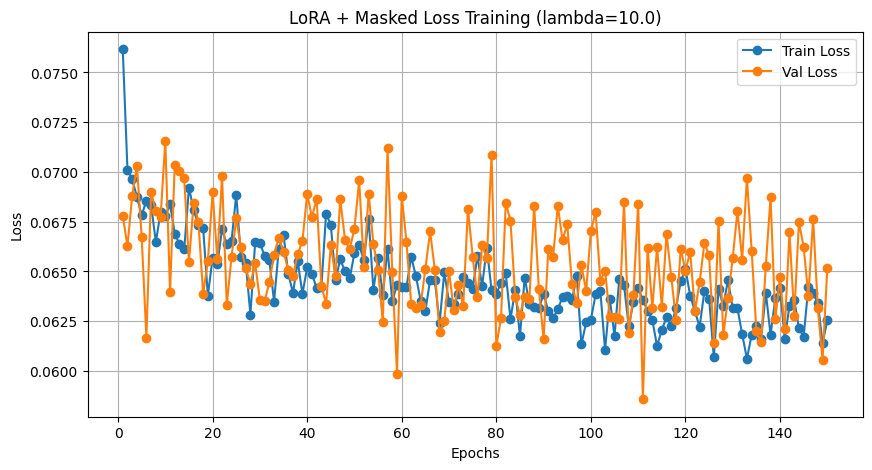

In [9]:
# ==========================================
# Cell 8: 学習曲線のプロット
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS + 1), history["train_loss"], label="Train Loss", marker='o')
plt.plot(range(1, NUM_EPOCHS + 1), history["val_loss"], label="Val Loss", marker='o')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"LoRA + Masked Loss Training (lambda={LAMBDA})")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"))
plt.show()